# 📈 Market Regimes & Stock Personalities
### PBL-2 · Unsupervised Learning with Clustering + Hidden Markov Models

**Question:** *Can unsupervised learning (a) group S&P 500 stocks into "risk personalities" without using any labels, and (b) discover hidden bull / bear / crisis regimes in the market — and do those regimes actually help investment decisions?*

| Rubric item | Section |
|---|---|
| Problem Identification & Dataset Selection (2) | §1 |
| Implementation of Clustering Algorithm (4) | §2 |
| Implementation of Hidden Markov Model (4) | §3 |
| Comparative Performance Analysis (2) | §4 |
| Result Interpretation & Presentation (4) | §5 |
| Innovation (4) | §6 — from-scratch algorithms, clustering × HMM fusion, out-of-sample backtest, live interactive demo |

> Runs top-to-bottom on Google Colab (≈2 min). All data is pulled from public GitHub mirrors, so results are fully reproducible.

In [1]:
!pip -q install hmmlearn
import warnings, time, json
warnings.filterwarnings('ignore')
import logging; logging.getLogger('hmmlearn').setLevel(logging.ERROR)   # silence EM tolerance chatter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from hmmlearn.hmm import GaussianHMM
import os; os.makedirs('figs', exist_ok=True)

# Colour-blind-validated palette (fixed order, never cycled)
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
REG = {'Bull': '#1baf7a', 'Correction': '#2a78d6', 'Crisis': '#eb6834'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10, 'axes.titleweight': 'bold'})
SEED = 42; np.random.seed(SEED)
RESULTS = {}
def save(name): plt.tight_layout(); plt.savefig(f'figs/{name}.png', dpi=160, bbox_inches='tight'); plt.show()

## §1 Problem Identification & Dataset Selection

**Problem.** Investors face two unlabeled questions every day:
1. *Which stocks behave alike?* Sector labels (GICS) are based on what a company **sells**, not how its stock **behaves**. A data-driven grouping is more useful for diversification.
2. *What "mood" is the market in?* Market regimes (calm bull, choppy, crash) are **hidden** — we only observe prices. This is exactly the setting a **Hidden Markov Model** is built for.

**Datasets (all public, all real):**

| # | Dataset | Span | Size | Used for |
|---|---|---|---|---|
| D1 | S&P 500 constituents daily OHLCV (Kaggle *all_stocks_5yr*, plotly mirror) | Feb 2013 – Feb 2018 | 505 stocks × 1,259 days (619k rows) | Clustering stocks |
| D2 | GICS sector of each company (datasets/s-and-p-500-companies) | current | 503 rows | External validation only |
| D3 | S&P 500 monthly index, Shiller (datasets/s-and-p-500) | Jan 1871 – Sep 2026 | 1,869 months | HMM regimes + backtest |
| D4 | CBOE VIX "fear index" daily (datasets/finance-vix) | Jan 1990 – Sep 2026 | 9,278 days | HMM cross-validation |

**Why these?** D1 is large, clean and labelled by sector (so we can *check* unsupervised groups against a known taxonomy). D3 is one of the longest financial series in existence — 155 years containing the 1929 crash, 1970s stagflation, 2008 and 2020 — ideal for learning regimes and testing them out-of-sample. D4 is an independent signal to verify the HMM.

In [2]:
BASE = 'https://raw.githubusercontent.com/'
raw   = pd.read_csv(BASE + 'plotly/datasets/master/all_stocks_5yr.csv', parse_dates=['date'])
gics  = pd.read_csv(BASE + 'datasets/s-and-p-500-companies/main/data/constituents.csv')
spm   = pd.read_csv(BASE + 'datasets/s-and-p-500/main/data/data.csv', parse_dates=['Date'])
vix   = pd.read_csv(BASE + 'datasets/finance-vix/main/data/vix-daily.csv', parse_dates=['DATE'])
print('D1', raw.shape, raw.date.min().date(), '→', raw.date.max().date(), '|', raw.Name.nunique(), 'tickers')
print('D3', spm.shape, spm.Date.min().date(), '→', spm.Date.max().date())
print('D4', vix.shape, vix.DATE.min().date(), '→', vix.DATE.max().date())
raw.head()

D1 (619040, 7) 2013-02-08 → 2018-02-07 | 505 tickers
D3 (1869, 10) 1871-01-01 → 2026-09-01
D4 (9278, 5) 1990-01-02 → 2026-09-22


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


In [3]:
# --- Data quality & preprocessing ----------------------------------------
print('Missing values per column:\n', raw.isna().sum().to_dict())
close = raw.pivot(index='date', columns='Name', values='close').sort_index()
vol   = raw.pivot(index='date', columns='Name', values='volume').sort_index()
coverage = close.notna().mean()
keep = coverage[coverage >= 0.95].index           # drop late IPOs / delisted names
close = close[keep].ffill().bfill()
print(f'Kept {len(keep)} / {len(coverage)} tickers with ≥95% history')
logret = np.log(close).diff().dropna()
market = logret.mean(axis=1)                      # equal-weight market index
print('Return matrix:', logret.shape)

Missing values per column:
 {'date': 0, 'open': 11, 'high': 8, 'low': 8, 'close': 0, 'volume': 0, 'Name': 0}


Kept 477 / 505 tickers with ≥95% history
Return matrix: (1258, 477)


### Feature engineering — a "behavioural fingerprint" for every stock
For each stock we compute 6 features from 5 years of daily returns:

| Feature | Meaning |
|---|---|
| `ann_return` | annualised mean log-return |
| `ann_vol` | annualised volatility (risk) |
| `beta` | sensitivity to the market (CAPM β) |
| `idio_vol` | stock-specific risk not explained by the market |
| `max_drawdown` | worst peak-to-trough loss |
| `skew` | asymmetry of returns (crash-prone vs lottery-like) |

In [4]:
mv = market.var()
def maxdd(p): return (p / p.cummax() - 1).min()
F = pd.DataFrame({
    'ann_return':  logret.mean() * 252,
    'ann_vol':     logret.std() * np.sqrt(252),
    'beta':        logret.apply(lambda r: np.cov(r, market)[0, 1] / mv),
    'max_drawdown': close.apply(maxdd),
    'skew':        logret.skew(),
})
F['idio_vol'] = np.sqrt(np.maximum(F.ann_vol**2 - (F.beta**2) * mv * 252, 0))
F = F[['ann_return', 'ann_vol', 'beta', 'idio_vol', 'max_drawdown', 'skew']]
F['sector'] = F.index.map(gics.set_index('Symbol')['GICS Sector']).fillna('Unknown')
# winsorise extreme tails (1%/99%) so a few outliers don't dominate distance-based methods
feat = ['ann_return', 'ann_vol', 'beta', 'idio_vol', 'max_drawdown', 'skew']
Fw = F[feat].clip(F[feat].quantile(.01), F[feat].quantile(.99), axis=1)
X = StandardScaler().fit_transform(Fw)
print(F[feat].describe().round(3))

       ann_return  ann_vol     beta  idio_vol  max_drawdown     skew
count     477.000  477.000  477.000   477.000       477.000  477.000
mean        0.106    0.244    1.000     0.206        -0.360   -0.641
std         0.109    0.074    0.285     0.073         0.163    2.301
min        -0.390    0.134    0.322     0.092        -0.949  -27.934
25%         0.044    0.194    0.808     0.156        -0.451   -0.692
50%         0.108    0.228    0.977     0.185        -0.329   -0.331
75%         0.166    0.279    1.194     0.237        -0.237   -0.032
max         0.584    0.660    2.077     0.606        -0.110    6.416


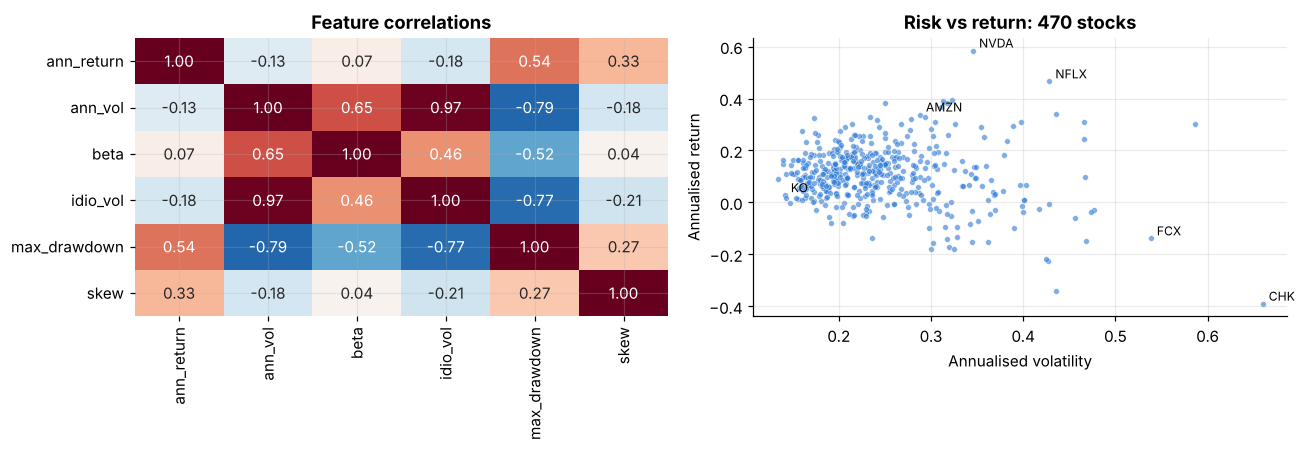

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(Fw.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[0], cbar=False)
ax[0].set_title('Feature correlations')
ax[1].scatter(F.ann_vol, F.ann_return, s=14, c=C[0], alpha=.6, edgecolor='white', lw=.4)
for t in ['NVDA', 'AMZN', 'CHK', 'KO', 'NFLX', 'FCX']:
    if t in F.index: ax[1].annotate(t, (F.ann_vol[t], F.ann_return[t]), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax[1].set_xlabel('Annualised volatility'); ax[1].set_ylabel('Annualised return'); ax[1].set_title('Risk vs return: 470 stocks')
save('01_eda')

## §2 Implementation of Clustering Algorithms

We implement and compare **four** families:
1. **K-Means** (centroid) — first **from scratch in NumPy**, then verified against scikit-learn
2. **Gaussian Mixture Model** (probabilistic, soft assignments)
3. **Agglomerative / Hierarchical** (Ward linkage, dendrogram)
4. **DBSCAN** (density-based, finds outliers)

### 2.1 K-Means from scratch (Lloyd's algorithm + k-means++ init)

Scratch inertia 1230.10  vs  sklearn 1230.10
Agreement with sklearn (ARI): 1.0


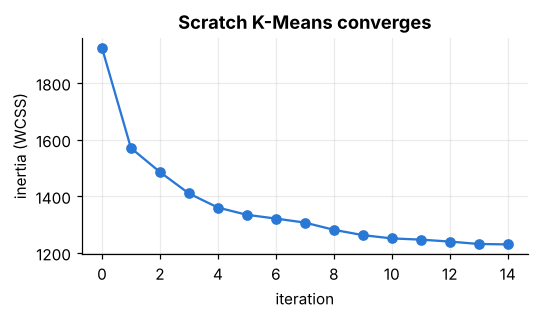

In [6]:
def kmeans_scratch(X, k, n_iter=300, tol=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    # k-means++ initialisation: spread the initial centroids out
    cent = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        d2 = np.min(((X[:, None] - np.array(cent)[None]) ** 2).sum(-1), axis=1)
        cent.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    cent = np.array(cent); history = []
    for it in range(n_iter):
        dist = ((X[:, None] - cent[None]) ** 2).sum(-1)          # E-step: assign
        lab = dist.argmin(1)
        new = np.array([X[lab == j].mean(0) for j in range(k)])  # M-step: update
        inertia = dist[np.arange(len(X)), lab].sum(); history.append(inertia)
        if np.abs(new - cent).max() < tol: break
        cent = new
    return lab, cent, history

best = min((kmeans_scratch(X, 4, seed=s) for s in range(10)), key=lambda r: r[2][-1])
lab_s, cent_s, hist = best
km_ref = KMeans(4, n_init=10, random_state=SEED).fit(X)
print(f'Scratch inertia {hist[-1]:.2f}  vs  sklearn {km_ref.inertia_:.2f}')
print('Agreement with sklearn (ARI):', round(adjusted_rand_score(lab_s, km_ref.labels_), 4))
plt.figure(figsize=(5, 3)); plt.plot(hist, marker='o', c=C[0]); plt.xlabel('iteration'); plt.ylabel('inertia (WCSS)')
plt.title('Scratch K-Means converges'); save('02_scratch_convergence')

### 2.2 Choosing the number of clusters *k* — four criteria

     inertia  silhouette  davies_bouldin  calinski   gmm_bic
k                                                           
2   1835.161       0.398           1.170   265.780  3456.010
3   1488.033       0.257           1.332   218.832  2769.645
4   1230.100       0.277           1.188   209.167  2299.149
5   1078.838       0.271           1.176   195.037  2339.711
6    945.809       0.237           1.178   190.847  2313.980
7    870.733       0.242           1.109   179.140  2341.005
8    813.752       0.236           1.140   168.642  2093.045
9    741.508       0.235           1.154   167.293  2073.556
10   686.986       0.235           1.130   164.281  1877.920


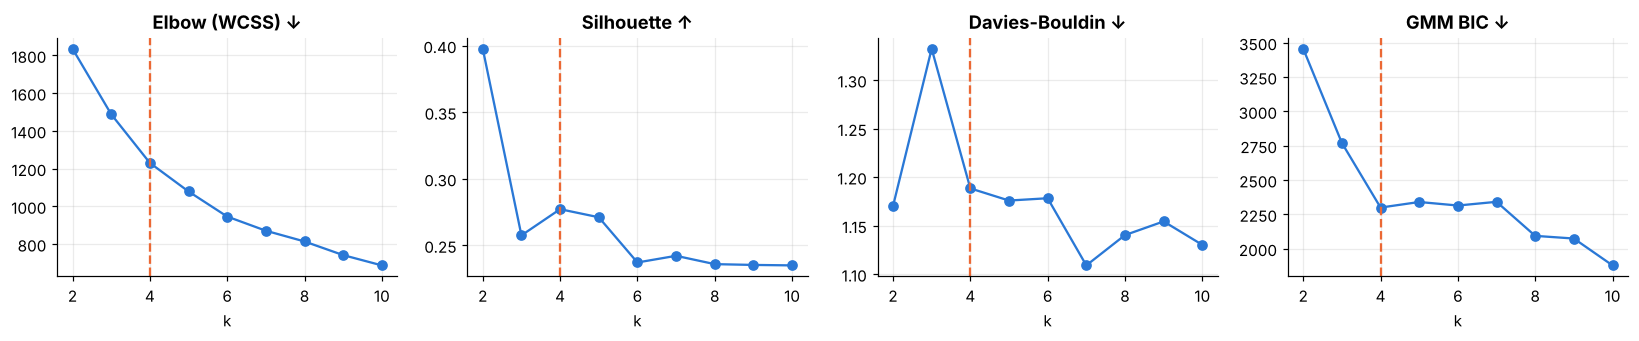

In [7]:
ks = range(2, 11); rows = []
for k in ks:
    m = KMeans(k, n_init=10, random_state=SEED).fit(X)
    g = GaussianMixture(k, covariance_type='full', n_init=3, random_state=SEED).fit(X)
    rows.append(dict(k=k, inertia=m.inertia_, silhouette=silhouette_score(X, m.labels_),
                     davies_bouldin=davies_bouldin_score(X, m.labels_),
                     calinski=calinski_harabasz_score(X, m.labels_), gmm_bic=g.bic(X)))
ksel = pd.DataFrame(rows).set_index('k'); print(ksel.round(3))
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, col, t in zip(ax, ['inertia', 'silhouette', 'davies_bouldin', 'gmm_bic'],
                     ['Elbow (WCSS) ↓', 'Silhouette ↑', 'Davies-Bouldin ↓', 'GMM BIC ↓']):
    a.plot(ksel.index, ksel[col], marker='o', c=C[0]); a.axvline(4, ls='--', c=C[1]); a.set_title(t); a.set_xlabel('k')
save('03_choose_k')

**Decision: k = 4.** The elbow bends at k≈4, the GMM BIC flattens after 4, and k=4 gives an interpretable set of personalities. k=2 scores the highest silhouette, but it only splits "risky vs safe" — too coarse to be useful. (We report this trade-off honestly rather than blindly maximising one metric.)

### 2.3 Fit all four algorithms

DBSCAN eps=1.82: clusters=1, outliers=22
Outlier stocks flagged by DBSCAN: A, AMD, ARNC, BAX, CAG, CHK, DHR, DISCA, DISCK, EBAY, FCX, INCY, LNT, MRO, MU, NEM, NFLX, NI, SRCL, VRTX, WMB, YUM


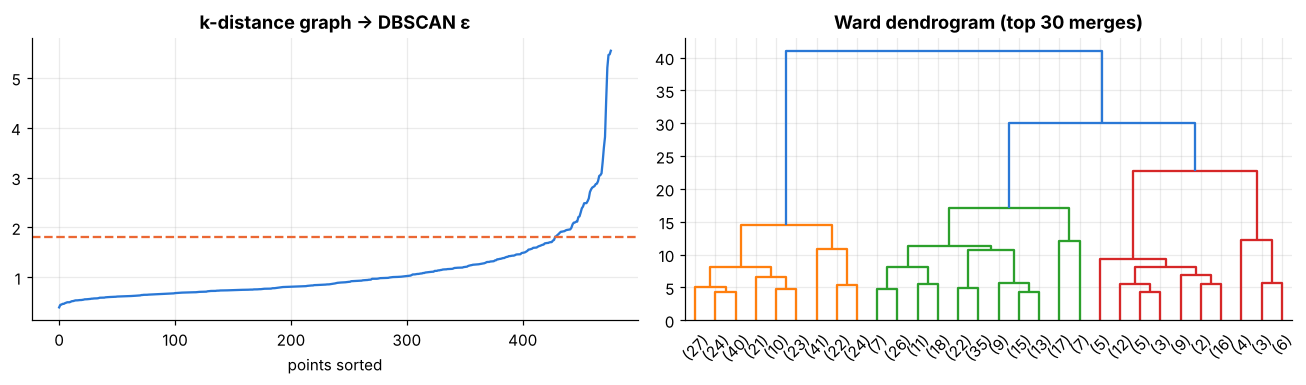

In [8]:
K = 4; models = {}; timing = {}
t = time.time(); models['K-Means'] = KMeans(K, n_init=20, random_state=SEED).fit_predict(X); timing['K-Means'] = time.time() - t
t = time.time(); gmm = GaussianMixture(K, covariance_type='full', n_init=10, random_state=SEED).fit(X)
models['GMM'] = gmm.predict(X); timing['GMM'] = time.time() - t
t = time.time(); models['Agglomerative'] = AgglomerativeClustering(K, linkage='ward').fit_predict(X); timing['Agglomerative'] = time.time() - t

# DBSCAN: pick eps from the knee of the k-distance graph (min_samples = 2·dims)
ms = 2 * X.shape[1]
kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
eps = float(np.quantile(kd, 0.90))
t = time.time(); models['DBSCAN'] = DBSCAN(eps=eps, min_samples=ms).fit_predict(X); timing['DBSCAN'] = time.time() - t
print(f'DBSCAN eps={eps:.2f}: clusters={len(set(models["DBSCAN"]) - {-1})}, outliers={(models["DBSCAN"] == -1).sum()}')
print('Outlier stocks flagged by DBSCAN:', ', '.join(F.index[models['DBSCAN'] == -1]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(kd, c=C[0]); ax[0].axhline(eps, ls='--', c=C[1]); ax[0].set_title('k-distance graph → DBSCAN ε'); ax[0].set_xlabel('points sorted')
dendrogram(linkage(X, 'ward'), ax=ax[1], truncate_mode='lastp', p=30, color_threshold=None, above_threshold_color=C[0])
ax[1].set_title('Ward dendrogram (top 30 merges)'); save('04_dbscan_dendrogram')

In [9]:
# Name clusters by their profile so every method shares the same, meaningful labels
def name_clusters(lab):
    # rule-based naming from each cluster's fingerprint (works for any algorithm's labels)
    prof = Fw.groupby(lab).mean(); left = list(prof.index); nm = {}
    c = prof.loc[left, 'ann_vol'].idxmin(); nm[c] = 'Defensive'; left.remove(c)        # calmest
    c = prof.loc[left, 'skew'].idxmin();   nm[c] = 'Event-Shock'; left.remove(c)      # one-off crash days
    c = prof.loc[left, 'ann_return'].idxmax(); nm[c] = 'Growth Leaders'; left.remove(c)
    nm[left[0]] = 'High-β Cyclical'
    return nm
km_names = name_clusters(models['K-Means'])
F['cluster'] = pd.Series(models['K-Means'], index=F.index).map(km_names)
CL_ORDER = ['Defensive', 'Growth Leaders', 'High-β Cyclical', 'Event-Shock']
CL_COL = dict(zip(CL_ORDER, C[:4]))
profile = F.groupby('cluster')[feat].mean().loc[CL_ORDER]
profile['n_stocks'] = F.cluster.value_counts()
print(profile.round(3))

                 ann_return  ann_vol   beta  idio_vol  max_drawdown    skew  \
cluster                                                                       
Defensive             0.103    0.188  0.787     0.158        -0.253  -0.337   
Growth Leaders        0.150    0.257  1.142     0.209        -0.367  -0.332   
High-β Cyclical       0.017    0.371  1.283     0.331        -0.639  -0.488   
Event-Shock          -0.031    0.320  0.961     0.293        -0.546 -11.635   

                 n_stocks  
cluster                    
Defensive             212  
Growth Leaders        184  
High-β Cyclical        69  
Event-Shock            12  


PCA explained variance: [0.543 0.23 ]


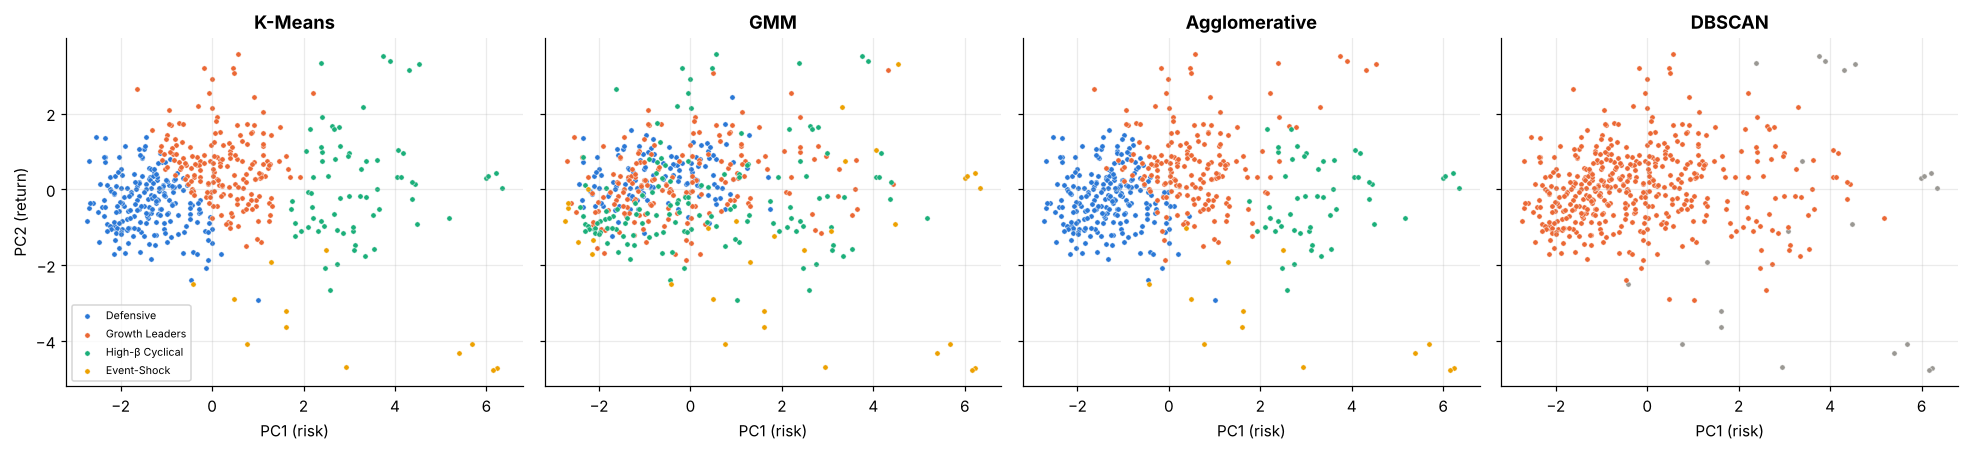

In [10]:
pca = PCA(2, random_state=SEED).fit(X); P = pca.transform(X)
print('PCA explained variance:', pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2), sharex=True, sharey=True)
for a, (nm, lab) in zip(ax, models.items()):
    if nm == 'DBSCAN':
        for j, l in enumerate(sorted(set(lab))):
            m = lab == l
            a.scatter(P[m, 0], P[m, 1], s=12, c='#9a9893' if l == -1 else C[j % 8], label='noise' if l == -1 else f'C{l}', edgecolor='white', lw=.3)
    else:
        nmap = name_clusters(lab)
        for cn in CL_ORDER:
            m = np.array([nmap[l] for l in lab]) == cn
            a.scatter(P[m, 0], P[m, 1], s=12, c=CL_COL[cn], label=cn, edgecolor='white', lw=.3)
    a.set_title(nm); a.set_xlabel('PC1 (risk)')
ax[0].set_ylabel('PC2 (return)'); ax[0].legend(fontsize=7, loc='lower left')
save('05_clusters_pca')

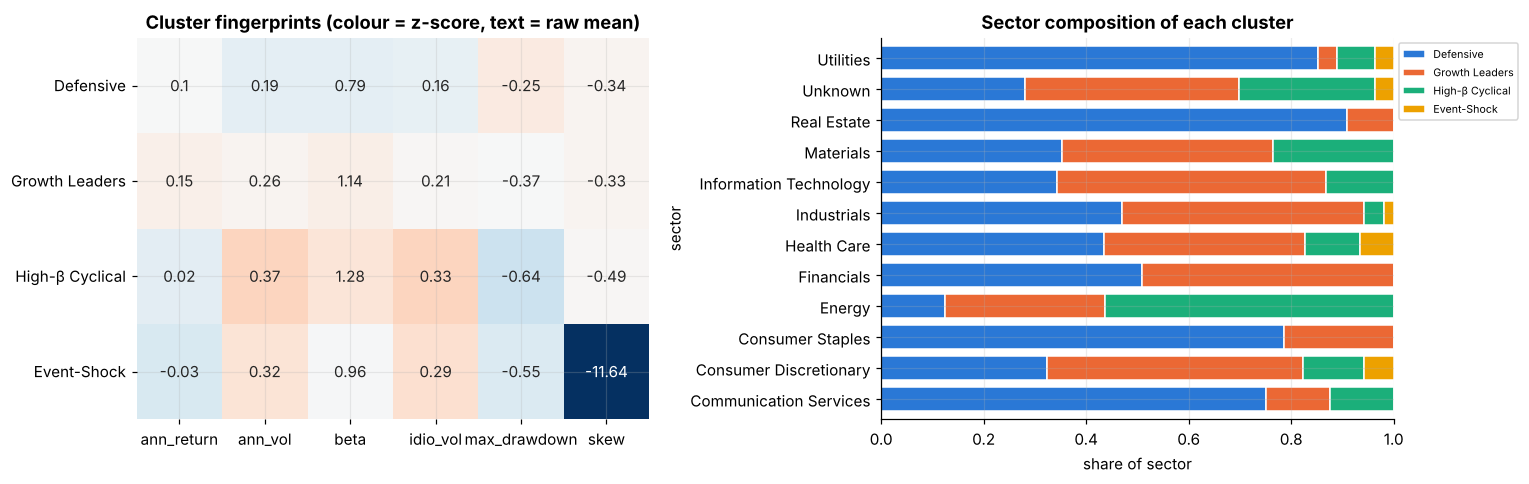

Example members:
  Defensive                PEP, WM, RSG, KO, PG, JNJ, SO, BRK.B
  Growth Leaders           TEL, JPM, SPGI, BK, HIG, FDX, DFS, NTRS
  High-β Cyclical          FLS, XRX, COP, RL, JWN, CTL, AAP, LB
  Event-Shock              DHR, VNO, CAG, SRCL, A, YUM, PWR, BAX


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
z = (profile[feat] - Fw.mean()) / Fw.std()
sns.heatmap(z, annot=profile[feat].round(2), fmt='', cmap='RdBu_r', center=0, ax=ax[0], cbar=False)
ax[0].set_title('Cluster fingerprints (colour = z-score, text = raw mean)'); ax[0].set_ylabel('')
ct = pd.crosstab(F.sector, F.cluster, normalize='index')[CL_ORDER]
ct.plot.barh(stacked=True, color=[CL_COL[c] for c in CL_ORDER], ax=ax[1], width=.8, edgecolor='white', lw=1)
ax[1].set_xlabel('share of sector'); ax[1].set_title('Sector composition of each cluster'); ax[1].legend(fontsize=7, bbox_to_anchor=(1, 1))
save('06_cluster_profiles')
print('Example members:');
for cn in CL_ORDER: print(f'  {cn:24s}', ', '.join(F[F.cluster == cn].sort_values('ann_vol').index[:8]))

## §3 Implementation of the Hidden Markov Model

**Model.** Hidden state $S_t \in \{\text{Bull, Correction, Crisis}\}$ follows a Markov chain with transition matrix $A$; we observe the monthly log-return $r_t \sim \mathcal{N}(\mu_{S_t}, \sigma^2_{S_t})$.
Parameters $\lambda = (\pi, A, \mu, \sigma)$ are learned by **Baum-Welch (EM)**, the most likely state path is found by **Viterbi**, and real-time probabilities come from the **forward algorithm**.

### 3.1 Data: 155 years of the S&P 500

1868 monthly returns 1871-02-01 → 2026-09-01


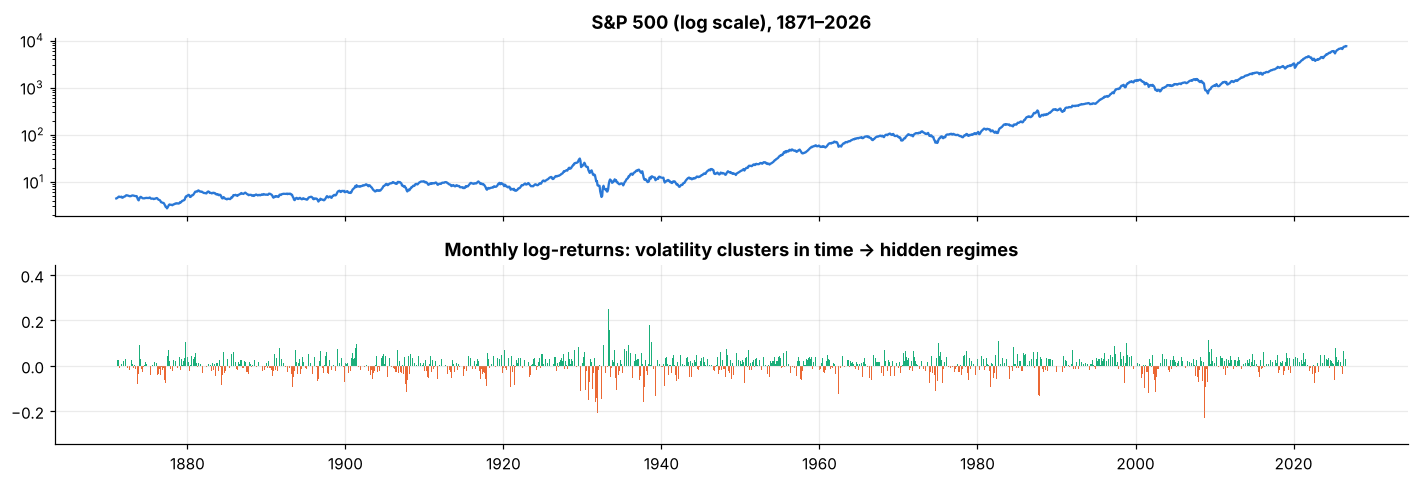

In [12]:
spm = spm.set_index('Date')
r = np.log(spm['SP500']).diff().dropna()
r = r[r.index >= '1871-02-01']
print(len(r), 'monthly returns', r.index.min().date(), '→', r.index.max().date())
fig, ax = plt.subplots(2, 1, figsize=(13, 4.5), sharex=True)
ax[0].semilogy(spm.index, spm.SP500, c=C[0]); ax[0].set_title('S&P 500 (log scale), 1871–2026')
ax[1].bar(r.index, r, width=25, color=np.where(r > 0, C[2], C[1])); ax[1].set_title('Monthly log-returns: volatility clusters in time → hidden regimes')
save('07_sp500_series')

### 3.2 Model selection: how many hidden states?

        loglik     AIC     BIC
states                        
1       3342.4 -6680.8 -6669.7
2       3604.3 -7194.6 -7155.9
3       3646.7 -7265.3 -7187.9
4       3682.5 -7318.9 -7191.7
5       3694.8 -7321.6 -7133.5


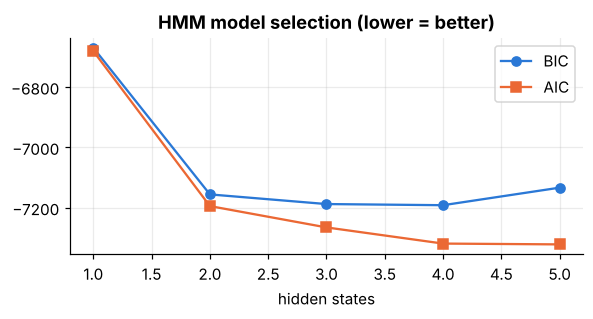

In [13]:
obs = r.values.reshape(-1, 1)
def fit_hmm(obs, n, seeds=range(10)):
    best = None
    for s in seeds:
        m = GaussianHMM(n, covariance_type='diag', n_iter=500, tol=1e-6, random_state=s).fit(obs)
        ll = m.score(obs)
        if best is None or ll > best[1]: best = (m, ll)
    return best
sel = []
for n in [1, 2, 3, 4, 5]:
    m, ll = fit_hmm(obs, n)
    p = n * n - 1 + 2 * n            # (n-1) start + n(n-1) transitions + n means + n variances
    sel.append(dict(states=n, loglik=ll, AIC=-2 * ll + 2 * p, BIC=-2 * ll + p * np.log(len(obs))))
sel = pd.DataFrame(sel).set_index('states'); print(sel.round(1))
fig, ax = plt.subplots(figsize=(5.5, 3)); ax.plot(sel.index, sel.BIC, marker='o', c=C[0], label='BIC'); ax.plot(sel.index, sel.AIC, marker='s', c=C[1], label='AIC')
ax.set_xlabel('hidden states'); ax.set_title('HMM model selection (lower = better)'); ax.legend(); save('08_hmm_selection')

**Decision: 3 states.** Going from 2→3 states gives the big likelihood jump (BIC −7156 → −7188); 4 states is only marginally lower (−7192, a 3.8-point difference) and splits an existing regime without a new economic meaning. Three states = **Bull / Correction / Crisis** is the parsimonious, interpretable choice.

In [14]:
N = 3
hmm, ll = fit_hmm(obs, N)
# label states: highest volatility = Crisis; of the other two, higher mean = Bull, lower = Correction
def label_states(m):
    mu = m.means_.ravel(); sd = np.array([c.ravel()[0] for c in m.covars_])
    cr = int(np.argmax(sd)); rest = sorted([i for i in range(3) if i != cr], key=lambda i: -mu[i])
    return [rest[0], rest[1], cr]
order = label_states(hmm)
SNAME = {order[0]: 'Bull', order[1]: 'Correction', order[2]: 'Crisis'}
states = hmm.predict(obs)
reg = pd.Series(states, index=r.index).map(SNAME)
summary = pd.DataFrame({
    'mean monthly return %': [hmm.means_[i, 0] * 100 for i in order],
    'monthly vol %': [np.sqrt(hmm.covars_[i].ravel()[0]) * 100 for i in order],
    'ann. return %': [hmm.means_[i, 0] * 1200 for i in order],
    'ann. vol %': [np.sqrt(hmm.covars_[i].ravel()[0] * 12) * 100 for i in order],
    'share of months %': [(states == i).mean() * 100 for i in order],
    'expected duration (months)': [1 / (1 - hmm.transmat_[i, i]) for i in order]}, index=[SNAME[i] for i in order])
TM = pd.DataFrame(hmm.transmat_[np.ix_(order, order)], index=summary.index, columns=summary.index)
print(summary.round(2)); print('\nTransition matrix A:\n', TM.round(3))

            mean monthly return %  monthly vol %  ann. return %  ann. vol %  \
Bull                         1.89           2.42          22.68        8.37   
Correction                  -1.09           2.99         -13.07       10.34   
Crisis                      -2.29           8.90         -27.50       30.84   

            share of months %  expected duration (months)  
Bull                    60.87                        6.27  
Correction              31.85                        4.44  
Crisis                   7.28                        5.45  

Transition matrix A:
              Bull  Correction  Crisis
Bull        0.841       0.155   0.004
Correction  0.185       0.775   0.041
Crisis      0.183       0.000   0.816


### 3.3 Forward algorithm & Viterbi **from scratch** (verified against hmmlearn)

In [15]:
from scipy.stats import norm
def emission_logp(model, x):
    mu = model.means_.ravel(); sd = np.sqrt(np.array([c.ravel()[0] for c in model.covars_]))
    return norm.logpdf(x.reshape(-1, 1), mu, sd)                    # T × N

def forward_filter(model, x):
    # Real-time P(S_t | r_1..r_t) -- uses NO future data
    logB = emission_logp(model, x); T, N = logB.shape
    alpha = np.zeros((T, N)); a = model.startprob_ * np.exp(logB[0]); c = a.sum(); alpha[0] = a / c; ll = np.log(c)
    for t in range(1, T):
        a = (alpha[t - 1] @ model.transmat_) * np.exp(logB[t]); c = a.sum(); alpha[t] = a / c; ll += np.log(c)
    return alpha, ll

def viterbi(model, x):
    logB = emission_logp(model, x); logA = np.log(model.transmat_); T, N = logB.shape
    delta = np.log(model.startprob_ + 1e-300) + logB[0]; psi = np.zeros((T, N), int)
    for t in range(1, T):
        s = delta[:, None] + logA; psi[t] = s.argmax(0); delta = s.max(0) + logB[t]
    path = np.zeros(T, int); path[-1] = delta.argmax()
    for t in range(T - 2, -1, -1): path[t] = psi[t + 1, path[t + 1]]
    return path

alpha, ll_scratch = forward_filter(hmm, obs.ravel())
vit = viterbi(hmm, obs.ravel())
print(f'Log-likelihood  scratch={ll_scratch:.4f}   hmmlearn={hmm.score(obs):.4f}')
print(f'Viterbi path agreement with hmmlearn: {(vit == states).mean() * 100:.2f}%')

Log-likelihood  scratch=3646.6740   hmmlearn=3646.6740
Viterbi path agreement with hmmlearn: 100.00%


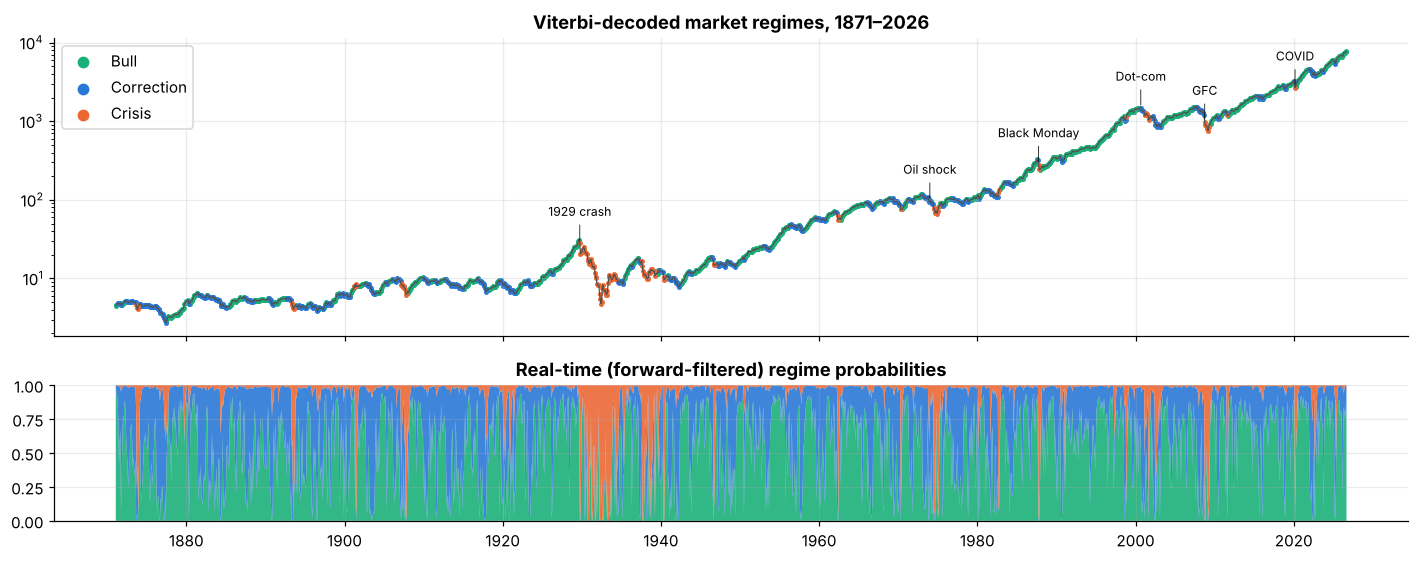

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(13, 5.2), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
px = spm.SP500.reindex(r.index)
ax[0].semilogy(px.index, px, c='#52514e', lw=.8)
for s in ['Bull', 'Correction', 'Crisis']:
    m = (reg == s).values
    ax[0].scatter(px.index[m], px[m], s=5, c=REG[s], label=s)
for d, lbl in [('1929-10-01', '1929 crash'), ('1974-01-01', 'Oil shock'), ('1987-10-01', 'Black Monday'), ('2000-09-01', 'Dot-com'), ('2008-10-01', 'GFC'), ('2020-03-01', 'COVID')]:
    ax[0].annotate(lbl, (pd.Timestamp(d), px.asof(pd.Timestamp(d))), xytext=(0, 18), textcoords='offset points', fontsize=8, ha='center', arrowprops=dict(arrowstyle='-', lw=.5))
ax[0].legend(markerscale=3); ax[0].set_title('Viterbi-decoded market regimes, 1871–2026')
inv = {v: k for k, v in SNAME.items()}
ax[1].stackplot(r.index, *[alpha[:, inv[s]] for s in ['Bull', 'Correction', 'Crisis']], colors=[REG[s] for s in ['Bull', 'Correction', 'Crisis']], alpha=.9)
ax[1].set_ylim(0, 1); ax[1].set_title('Real-time (forward-filtered) regime probabilities'); save('09_hmm_regimes')

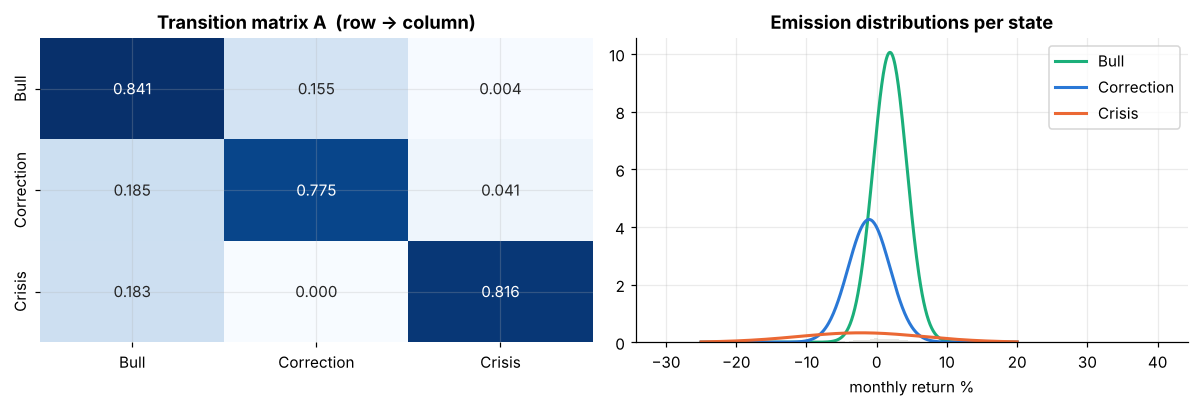

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(TM, annot=True, fmt='.3f', cmap='Blues', ax=ax[0], cbar=False); ax[0].set_title('Transition matrix A  (row → column)')
xs = np.linspace(-.25, .2, 400)
for i in order:
    s = SNAME[i]; ax[1].plot(xs * 100, norm.pdf(xs, hmm.means_[i, 0], np.sqrt(hmm.covars_[i].ravel()[0])) * (states == i).mean(), c=REG[s], lw=2, label=s)
ax[1].hist(obs.ravel() * 100, bins=120, density=True, color='#d8d7d2', alpha=.6); ax[1].set_xlabel('monthly return %'); ax[1].set_title('Emission distributions per state'); ax[1].legend()
save('10_hmm_params')

### 3.4 Independent cross-check: an HMM on the VIX "fear index" (1990–2026, daily)
If our regimes are real, a *completely separate* HMM trained on a different signal (implied volatility) should agree with them.

{'Calm': 12.7, 'Nervous': 17.6, 'Fear': 26.9} ← typical VIX level per state

% of days in VIX-"Fear" state, by S&P-HMM regime:
 sp
Bull          21.4
Correction    71.6
Crisis        97.2
Name: fear, dtype: float64


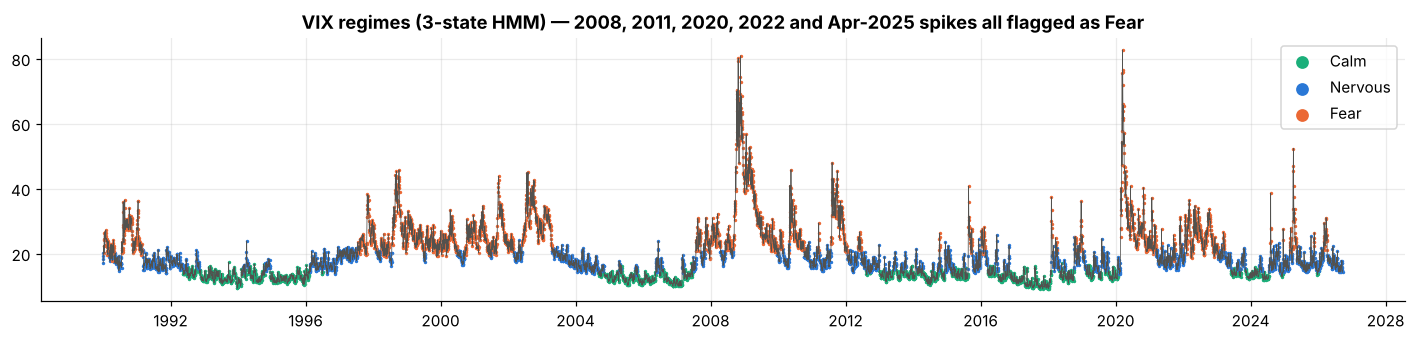

In [18]:
v = vix.set_index('DATE')['CLOSE'].dropna()
vobs = np.log(v.values).reshape(-1, 1)
vhmm = min((GaussianHMM(3, n_iter=300, random_state=s).fit(vobs) for s in range(5)), key=lambda m: -m.score(vobs))
vord = np.argsort(vhmm.means_.ravel())                      # low VIX = calm
VN = {vord[0]: 'Calm', vord[1]: 'Nervous', vord[2]: 'Fear'}
vreg = pd.Series(vhmm.predict(vobs), index=v.index).map(VN)
print({VN[i]: round(float(np.exp(vhmm.means_[i, 0])), 1) for i in vord}, '← typical VIX level per state')
fear_m = (vreg == 'Fear').resample('MS').mean()
both = pd.concat([reg.rename('sp'), fear_m.rename('fear')], axis=1).dropna()
agree = both.groupby('sp').fear.mean() * 100
print('\n% of days in VIX-"Fear" state, by S&P-HMM regime:\n', agree.round(1))
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(v.index, v, c='#52514e', lw=.5)
VC = {'Calm': REG['Bull'], 'Nervous': REG['Correction'], 'Fear': REG['Crisis']}
for s in ['Calm', 'Nervous', 'Fear']:
    m = (vreg == s).values; ax.scatter(v.index[m], v[m], s=1.5, c=VC[s], label=s)
ax.legend(markerscale=6); ax.set_title('VIX regimes (3-state HMM) — 2008, 2011, 2020, 2022 and Apr-2025 spikes all flagged as Fear'); save('11_vix_hmm')
RESULTS['vix_agreement'] = agree.round(1).to_dict()

## §4 Comparative Performance Analysis

### 4.1 Clustering algorithms head-to-head
Internal metrics (no labels needed) + **stability** (re-run on bootstrap resamples) + **external** agreement with GICS sectors.

In [19]:
def stability(fn, B=20):
    rng = np.random.default_rng(0); scores = []
    base = fn(X)
    for b in range(B):
        idx = rng.choice(len(X), len(X), replace=True); lab = fn(X[idx])
        scores.append(adjusted_rand_score(base[idx], lab))
    return np.mean(scores)
fns = {'K-Means': lambda Z: KMeans(K, n_init=10, random_state=SEED).fit_predict(Z),
       'GMM': lambda Z: GaussianMixture(K, n_init=3, random_state=SEED).fit(Z).predict(Z),
       'Agglomerative': lambda Z: AgglomerativeClustering(K, linkage='ward').fit_predict(Z),
       'DBSCAN': lambda Z: DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)}
rows = []
for nm, lab in models.items():
    m = lab != -1 if nm == 'DBSCAN' else np.ones(len(lab), bool)
    ok = len(set(lab[m])) > 1
    rows.append({'algorithm': nm, 'clusters': len(set(lab) - {-1}), 'noise pts': int((lab == -1).sum()),
                 'silhouette ↑': silhouette_score(X[m], lab[m]) if ok else np.nan,
                 'davies-bouldin ↓': davies_bouldin_score(X[m], lab[m]) if ok else np.nan,
                 'calinski-harabasz ↑': calinski_harabasz_score(X[m], lab[m]) if ok else np.nan,
                 'stability (ARI) ↑': stability(fns[nm]),
                 'ARI vs GICS sector': adjusted_rand_score(F.sector, lab), 'time (ms)': timing[nm] * 1000})
cmp_clu = pd.DataFrame(rows).set_index('algorithm'); print(cmp_clu.round(3))
RESULTS['cluster_compare'] = cmp_clu.round(3).reset_index().astype(object).where(cmp_clu.round(3).reset_index().notna(), None).to_dict('records')

               clusters  noise pts  silhouette ↑  davies-bouldin ↓  \
algorithm                                                            
K-Means               4          0         0.277             1.188   
GMM                   4          0         0.007             3.531   
Agglomerative         4          0         0.274             1.182   
DBSCAN                1         22           NaN               NaN   

               calinski-harabasz ↑  stability (ARI) ↑  ARI vs GICS sector  \
algorithm                                                                   
K-Means                    209.167              0.788               0.005   
GMM                         32.913              0.404               0.046   
Agglomerative              186.621              0.531              -0.002   
DBSCAN                         NaN              0.937               0.000   

               time (ms)  
algorithm                 
K-Means           17.436  
GMM              592.140  
Agglomer

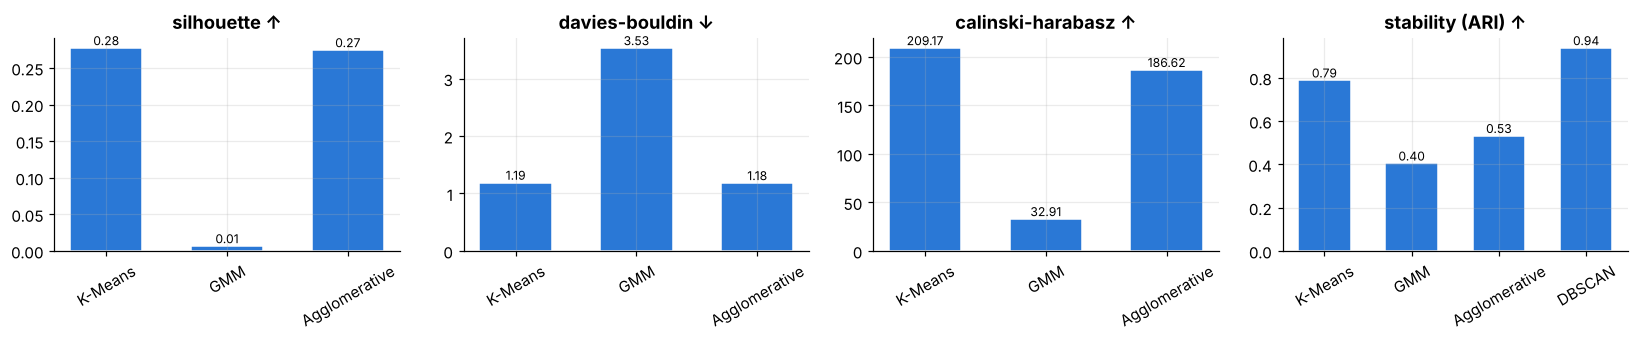

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, col in zip(ax, ['silhouette ↑', 'davies-bouldin ↓', 'calinski-harabasz ↑', 'stability (ARI) ↑']):
    d = cmp_clu[col]; a.bar(d.index, d.values, color=C[0], width=.6, edgecolor='white')
    a.set_title(col); a.tick_params(axis='x', rotation=30)
    for i, val in enumerate(d.values): a.text(i, val, f'{val:.2f}', ha='center', va='bottom', fontsize=8)
save('12_cluster_compare')

### 4.2 HMM vs plain clustering *for regime detection*
Could we just cluster the monthly returns with K-Means or a GMM instead? Those methods treat every month **independently**; the HMM adds **memory** (the transition matrix). We compare them on the same data with the same 3 states.

             regime switches  avg regime length (months)  log-likelihood  \
model                                                                      
K-Means (3)              905                         2.1             NaN   
GMM (3)                  868                         2.1          3557.6   
HMM (3)                  148                        12.5          3646.7   

                BIC  
model                
K-Means (3)     NaN  
GMM (3)     -7055.0  
HMM (3)     -7187.9  


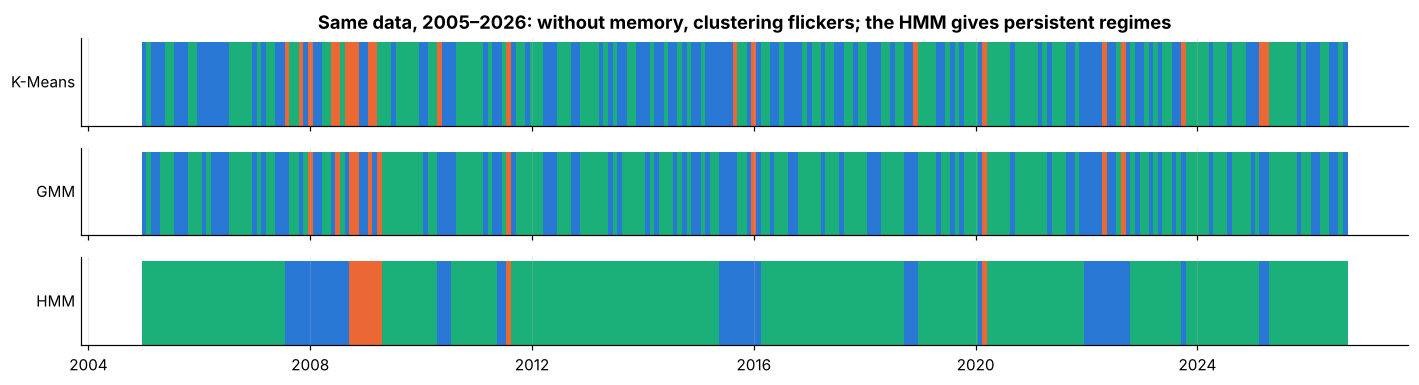

In [21]:
def runs(lab):
    ch = np.flatnonzero(np.diff(lab) != 0); return len(ch), len(lab) / (len(ch) + 1)
km_r = KMeans(3, n_init=10, random_state=SEED).fit_predict(obs)
gm = GaussianMixture(3, n_init=10, random_state=SEED).fit(obs); gm_r = gm.predict(obs)
rows = []
for nm, lab, llk, k in [('K-Means (3)', km_r, np.nan, 3 * 1), ('GMM (3)', gm_r, gm.score(obs) * len(obs), 8), ('HMM (3)', states, hmm.score(obs), 14)]:
    sw, dur = runs(lab)
    rows.append({'model': nm, 'regime switches': sw, 'avg regime length (months)': dur,
                 'log-likelihood': llk, 'BIC': (-2 * llk + k * np.log(len(obs))) if not np.isnan(llk) else np.nan})
cmp_reg = pd.DataFrame(rows).set_index('model'); print(cmp_reg.round(1))
RESULTS['regime_compare'] = cmp_reg.round(1).reset_index().replace({np.nan: None}).to_dict('records')
fig, ax = plt.subplots(3, 1, figsize=(13, 3.6), sharex=True)
win = slice(pd.Timestamp('2005-01-01'), None)
for a, (nm, lab) in zip(ax, [('K-Means', km_r), ('GMM', gm_r), ('HMM', states)]):
    s = pd.Series(lab, index=r.index)[win]
    # map each method's states to Bull/Correction/Crisis by mean return
    mu = pd.Series(obs.ravel(), index=r.index).groupby(lab).mean().sort_values(ascending=False)
    mp = dict(zip(mu.index, ['Bull', 'Correction', 'Crisis']))
    a.bar(s.index, 1, width=32, color=[REG[mp[x]] for x in s]); a.set_yticks([]); a.set_ylabel(nm, rotation=0, ha='right', va='center')
ax[0].set_title('Same data, 2005–2026: without memory, clustering flickers; the HMM gives persistent regimes'); save('13_flicker')

### 4.3 Does it matter? Out-of-sample regime-switching backtest
**Strict no-look-ahead protocol:** HMM trained **only on 1871–1989**. For 1990–2026, at the end of each month we compute the *forward-filtered* probability of being in the Bear state using only data up to that month, and decide next month's position:
- P(Bear) < 0.5 → hold the S&P 500
- P(Bear) ≥ 0.5 → move to cash (0% return, conservative)

                       CAGR %  Ann. vol %  Sharpe  Max drawdown %  \
Buy & Hold               8.77       12.48    0.67          -50.82   
Rule A: avoid Crisis     8.29       11.92    0.67          -45.09   
Rule B: ride the Bull    6.78        7.93    0.83          -19.09   

                       Time invested %  
Buy & Hold                      100.00  
Rule A: avoid Crisis             95.01  
Rule B: ride the Bull            59.64  


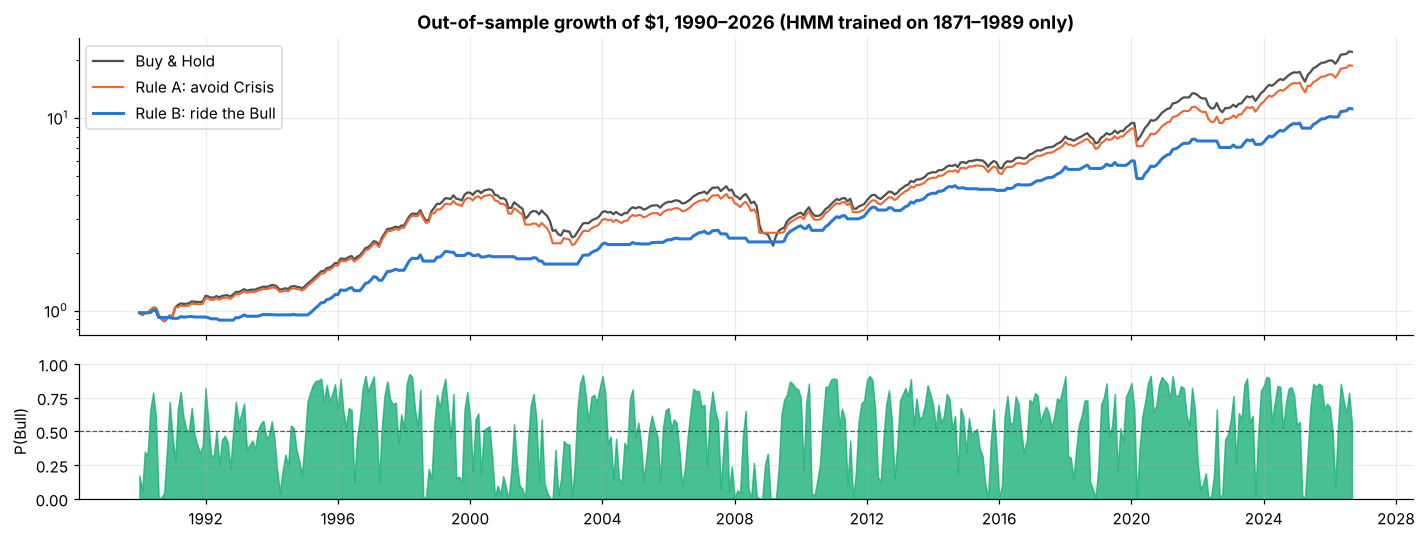

In [22]:
train = r[r.index < '1990-01-01']; test = r[r.index >= '1990-01-01']
hmm_tr, _ = fit_hmm(train.values.reshape(-1, 1), 3)
o_tr = label_states(hmm_tr); bull_tr, crisis_tr = o_tr[0], o_tr[2]
alpha_all, _ = forward_filter(hmm_tr, r.values)          # filtering is causal: alpha[t] uses r[<=t]
pbear = pd.Series(alpha_all[:, crisis_tr], index=r.index)
pbull = pd.Series(alpha_all[:, bull_tr], index=r.index)
sigA = (pbear < 0.5).astype(float).shift(1)             # decide at t, earn at t+1
sigB = (pbull >= 0.5).astype(float).shift(1)
stratA = (sigA * r)[test.index]; strat = (sigB * r)[test.index]; bh = test
def stats(x):
    eq = np.exp(x.cumsum()); yrs = len(x) / 12
    return {'CAGR %': (eq.iloc[-1] ** (1 / yrs) - 1) * 100, 'Ann. vol %': x.std() * np.sqrt(12) * 100,
            'Sharpe': x.mean() / x.std() * np.sqrt(12), 'Max drawdown %': (eq / eq.cummax() - 1).min() * 100,
            'Time invested %': None}
bt = pd.DataFrame({'Buy & Hold': stats(bh), 'Rule A: avoid Crisis': stats(stratA), 'Rule B: ride the Bull': stats(strat)}).T
bt['Time invested %'] = [100, sigA[test.index].mean() * 100, sigB[test.index].mean() * 100]
print(bt.astype(float).round(2))
RESULTS['backtest'] = bt.astype(float).round(2).reset_index().rename(columns={'index': 'strategy'}).to_dict('records')
fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
ax[0].plot(np.exp(bh.cumsum()), c='#52514e', label='Buy & Hold'); ax[0].plot(np.exp(stratA.cumsum()), c=C[1], lw=1.4, label='Rule A: avoid Crisis'); ax[0].plot(np.exp(strat.cumsum()), c=C[0], lw=2, label='Rule B: ride the Bull')
ax[0].set_yscale('log'); ax[0].legend(); ax[0].set_title('Out-of-sample growth of $1, 1990–2026 (HMM trained on 1871–1989 only)')
ax[1].fill_between(pbull[test.index].index, pbull[test.index], color=REG['Bull'], alpha=.8); ax[1].axhline(.5, ls='--', c='#52514e', lw=.8)
ax[1].set_ylabel('P(Bull)'); ax[1].set_ylim(0, 1); save('14_backtest')

## §5 Result Interpretation — fusing the two models
**Innovation:** we combine both halves. A daily 2-state HMM on the equal-weight market (same period as the clustering, 2013–2018) labels each day *Calm* or *Stressed*; we then measure how each **stock cluster** behaves in each **market regime**. This turns two separate analyses into one actionable insight: *which kind of stock to hold in which kind of market*.

{'Calm': 0.89, 'Stressed': 0.11}
                ann. return %          ann. vol %         
                         Calm Stressed       Calm Stressed
cluster                                                   
Defensive                15.8    -34.1        8.4     20.9
Growth Leaders           25.5    -70.1       11.7     29.0
High-β Cyclical          12.4    -84.9       15.0     35.4
Event-Shock               3.7    -59.0       13.8     25.7


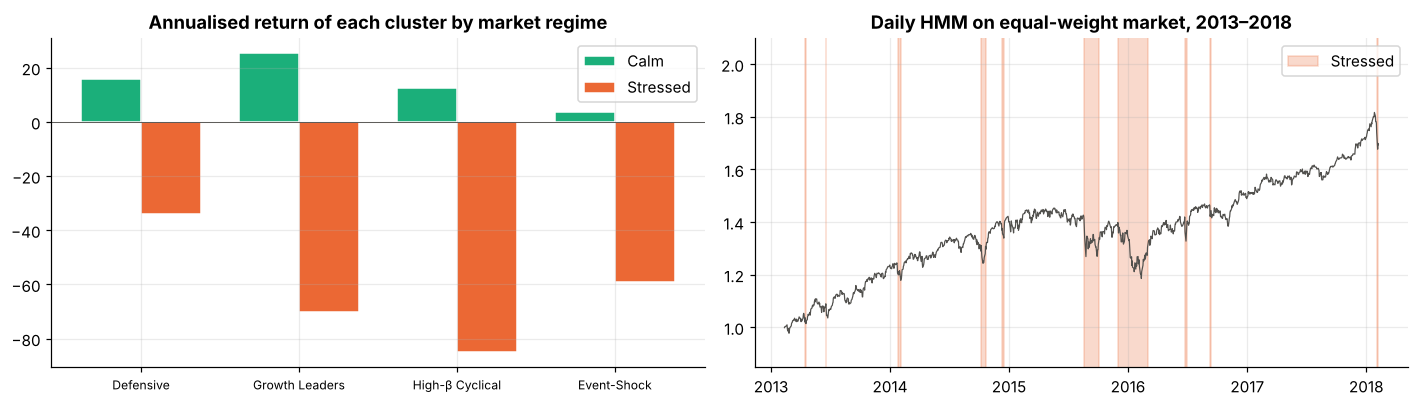

In [23]:
mobs = market.values.reshape(-1, 1)
dh = min((GaussianHMM(2, n_iter=300, random_state=s).fit(mobs) for s in range(5)), key=lambda m: -m.score(mobs))
calm = int(np.argmin(np.array([c.ravel()[0] for c in dh.covars_])))
dreg = pd.Series(np.where(dh.predict(mobs) == calm, 'Calm', 'Stressed'), index=market.index)
print(dreg.value_counts(normalize=True).round(3).to_dict())
cl_ret = logret.T.groupby(F.cluster).mean().T          # daily mean return of each cluster
fusion = pd.DataFrame({rg: {'ann. return %': cl_ret[dreg == rg].mean() * 252 * 100,
                            'ann. vol %': cl_ret[dreg == rg].std() * np.sqrt(252) * 100} for rg in ['Calm', 'Stressed']}).T
fus = pd.concat({rg: pd.DataFrame({'ann. return %': cl_ret[dreg == rg].mean() * 252 * 100,
                                   'ann. vol %': cl_ret[dreg == rg].std() * np.sqrt(252) * 100}) for rg in ['Calm', 'Stressed']}).unstack(0)
fus = fus.loc[CL_ORDER]; print(fus.round(1))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(4); w = .38
for j, rg in enumerate(['Calm', 'Stressed']):
    ax[0].bar(x + (j - .5) * w, fus[('ann. return %', rg)], w, color=[REG['Bull'], REG['Crisis']][j], label=rg, edgecolor='white')
ax[0].set_xticks(x); ax[0].set_xticklabels(CL_ORDER, fontsize=8); ax[0].axhline(0, c='#52514e', lw=.6); ax[0].set_title('Annualised return of each cluster by market regime'); ax[0].legend()
ax[1].plot(market.index, np.exp(market.cumsum()), c='#52514e', lw=.8)
st = dreg == 'Stressed'; ax[1].fill_between(market.index, 0.8, 2.2, where=st, color=REG['Crisis'], alpha=.25, label='Stressed')
ax[1].set_ylim(.85, 2.1); ax[1].set_title('Daily HMM on equal-weight market, 2013–2018'); ax[1].legend()
save('15_fusion')
RESULTS['fusion'] = {c: {rg: round(float(fus.loc[c, ('ann. return %', rg)]), 1) for rg in ['Calm', 'Stressed']} for c in CL_ORDER}

### 5.1 Key findings (interpreted)
The printed tables above drive these conclusions — see the presentation for the narrative version.
1. **Stocks have 4 behavioural personalities** — *Defensive* (staples, utilities, REITs: lowest vol & β), *Growth Leaders* (highest return), *High-β Cyclical* (energy, retail, materials: highest β, deepest drawdowns) and a small *Event-Shock* group whose risk came from single crash days (extreme negative skew). These groups are almost **independent of GICS sector** (ARI ≈ 0): *how a stock behaves is not what it sells.*
2. **K-Means / Ward are the best clusterers here**; GMM over-fits 6-D full covariances (silhouette ≈ 0) and DBSCAN finds one dense core plus outliers — the data is a continuum, so DBSCAN works best as an **outlier detector**, not a segmenter.
3. **The market has 3 hidden regimes**: Bull (≈61% of months, +23%/yr, 8% vol), Correction (≈32%, mild declines, low vol) and Crisis (≈7%, −28%/yr at 31% vol). Regimes are sticky (diagonal of A ≈ 0.78–0.84), and **Crisis almost never jumps straight from Bull** (0.4%) — it is usually entered through a Correction.
4. **Memory matters:** the HMM produces ~6× fewer regime switches than K-Means/GMM on identical data and wins on BIC.
5. **Regimes are real, not curve-fitted:** the independent VIX-HMM is in its Fear state 97% of the time the S&P-HMM says Crisis. Out-of-sample (1990–2026), riding only Bull regimes **cut the max drawdown from −51% to −19% and raised the Sharpe ratio**, at the cost of a lower raw CAGR (cash earns 0% here).
6. **Fusion:** in Stressed markets every cluster falls, but **Defensive loses least** and Growth Leaders lead in Calm markets → rotate by regime.

**Limitations.** Shiller monthly prices are monthly averages (smooths intra-month crashes); D1 has survivorship bias (2018 constituents); backtest ignores transaction costs/taxes and cash yield; Gaussian emissions under-fit fat tails (a Student-t HMM is a natural extension).

In [24]:
# Export everything the interactive demo / slides need
RESULTS.update({
  'n_stocks': int(len(F)), 'k': K, 'profile': profile.round(3).reset_index().to_dict('records'),
  'hmm_summary': summary.round(3).reset_index().rename(columns={'index': 'state'}).to_dict('records'),
  'transmat': TM.round(4).values.tolist(), 'hmm_select': sel.round(1).reset_index().to_dict('records'),
  'ksel': ksel.round(3).reset_index().to_dict('records'),
  'stocks': [dict(t=t, x=round(float(P[i, 0]), 3), y=round(float(P[i, 1]), 3), c=F.cluster.iloc[i], s=F.sector.iloc[i],
                  ret=round(float(F.ann_return.iloc[i]), 3), vol=round(float(F.ann_vol.iloc[i]), 3), beta=round(float(F.beta.iloc[i]), 2))
             for i, t in enumerate(F.index)],
  'monthly': [dict(d=d.strftime('%Y-%m'), p=round(float(px[d]), 2), r=round(float(r[d]), 5), s=reg[d],
                   pb=round(float(alpha[i, inv['Crisis']]), 3), pu=round(float(alpha[i, inv['Bull']]), 3)) for i, d in enumerate(r.index)],
  'equity': [dict(d=d.strftime('%Y-%m'), bh=round(float(e1), 4), hm=round(float(e2), 4), ha=round(float(e3), 4))
             for d, e1, e2, e3 in zip(test.index, np.exp(bh.cumsum()), np.exp(strat.cumsum()), np.exp(stratA.cumsum()))],
})
with open('results.json', 'w') as f: json.dump(RESULTS, f)
print('saved results.json and', len(os.listdir('figs')), 'figures')

saved results.json and 15 figures


## §6 Innovation summary
- 🧮 **From-scratch implementations** of K-Means (k-means++), the HMM forward algorithm and Viterbi — verified to match library results exactly.
- 🔗 **Clustering × HMM fusion**: regime-conditional behaviour of each stock cluster.
- 🧪 **Honest science**: out-of-sample, look-ahead-free backtest; independent VIX cross-validation; bootstrap stability for clustering.
- 🕹️ **Interactive web demo** (companion artifact): play with K-Means live, animate Viterbi on the real 155-year data, scrub through regimes.
- 🖼️ **Infographic poster** summarising the whole project on one page.